# Weather, demand forecast, and a blend

The day-ahead inputs come from three places: the clock and recent carbon, yesterday's weather, and CAISO's demand forecast. They share a timestamp, so the useful comparison is whether one model should see every column, or whether a weather model and a demand model should be fit separately and averaged.

Three specialists, each of which sees the clock and recent carbon:

- History only, linear. This is the diurnal shape plus persistence.
- History plus yesterday's weather, a tree. Weather's link with carbon depends on the hour, which is the interaction a tree can split on.
- History plus the demand forecast, linear. Given the hour, that link is close to a slope.

Blend weights are a grid with steps of 0.1. They are chosen on the last 14 days of the training block, then frozen. Specialists are refit on the whole training block before the holdout is scored. Early fusion is one ridge model and one tree that see every day-ahead column. The holdout is not used to pick weights, penalties, or the blend.

In [1]:
%matplotlib inline

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 12

from sklearn.linear_model import Ridge

from src.modeling import (
    DAY_AHEAD_CATEGORICAL,
    DAY_AHEAD_NUMERIC,
    DEMAND_FORECAST,
    HISTORY,
    HOUR_DOW,
    SEASON,
    WEATHER_LAG,
    feature_matrix,
    fit_tree,
    fit_validation_split,
    linear_pipeline,
    predict_tree,
    search_time_series,
)

from src.carbon_data import load_model_frame
from src.modeling import TARGET, hour_climatology, result_row, score_predictions, train_test_split

frame = load_model_frame()
train, test = train_test_split(frame)
assert train.index.max() < test.index.min()
baseline = hour_climatology(train, test)
baseline_mae = score_predictions(test[TARGET], baseline)["mae"]
print(f"{len(frame)} hours, {frame.index.min():%Y-%m-%d} to {frame.index.max():%Y-%m-%d} UTC")
print(
    f"train {len(train)} hours through {train.index.max():%Y-%m-%d %H} UTC; "
    f"test {len(test)} hours from {test.index.min():%Y-%m-%d %H} UTC"
)
print(f"hour-of-day baseline MAE on the test block: {baseline_mae:.2f} g/kWh")

SPECIALISTS = {
    "history": (HOUR_DOW, SEASON + HISTORY, "ridge"),
    "weather": (HOUR_DOW, SEASON + HISTORY + WEATHER_LAG, "tree"),
    "demand forecast": (HOUR_DOW, SEASON + HISTORY + DEMAND_FORECAST, "ridge"),
}
fit_rows, valid_rows = fit_validation_split(train)
print(
    f"weight selection uses {len(valid_rows)} hours, "
    f"{valid_rows.index.min():%Y-%m-%d} to {valid_rows.index.max():%Y-%m-%d} UTC, inside the training block"
)



6793 hours, 2026-01-08 to 2026-10-18 UTC
train 6120 hours through 2026-09-20 22 UTC; test 673 hours from 2026-09-20 23 UTC
hour-of-day baseline MAE on the test block: 70.62 g/kWh
weight selection uses 337 hours, 2026-09-06 to 2026-09-20 UTC, inside the training block


## Choose weights on the training tail

Ridge penalties are chosen on the earlier training hours. The tree has no penalty search here; its size is the shared one. Validation predictions come from models that have not seen the validation tail.

In [2]:
def choose_alpha(categorical, numeric, rows):
    search = search_time_series(
        linear_pipeline(Ridge(), categorical, numeric),
        {"model__alpha": [0.01, 0.1, 1.0, 10.0, 100.0]},
        feature_matrix(rows, categorical, numeric),
        rows[TARGET],
    )
    return search.best_params_["model__alpha"]


def ridge_predict(categorical, numeric, alpha, source, target_rows):
    model = linear_pipeline(Ridge(alpha=alpha), categorical, numeric)
    model.fit(feature_matrix(source, categorical, numeric), source[TARGET])
    return model.predict(feature_matrix(target_rows, categorical, numeric))


alphas = {}
valid_predictions = {}
for name, (categorical, numeric, family) in SPECIALISTS.items():
    if family == "ridge":
        alphas[name] = choose_alpha(categorical, numeric, fit_rows)
        valid_predictions[name] = ridge_predict(categorical, numeric, alphas[name], fit_rows, valid_rows)
    else:
        model = fit_tree(fit_rows, categorical, numeric, loss="absolute_error")
        valid_predictions[name] = predict_tree(model, valid_rows, categorical, numeric)

early_alpha = choose_alpha(DAY_AHEAD_CATEGORICAL, DAY_AHEAD_NUMERIC, fit_rows)
valid_predictions["early ridge"] = ridge_predict(
    DAY_AHEAD_CATEGORICAL, DAY_AHEAD_NUMERIC, early_alpha, fit_rows, valid_rows
)
early_tree = fit_tree(fit_rows, DAY_AHEAD_CATEGORICAL, DAY_AHEAD_NUMERIC, loss="absolute_error")
valid_predictions["early tree"] = predict_tree(
    early_tree, valid_rows, DAY_AHEAD_CATEGORICAL, DAY_AHEAD_NUMERIC
)

weight_rows = []
for history_steps in range(11):
    for weather_steps in range(11 - history_steps):
        weights = {
            "history": history_steps / 10,
            "weather": weather_steps / 10,
            "demand forecast": (10 - history_steps - weather_steps) / 10,
        }
        blended = sum(weights[name] * valid_predictions[name] for name in SPECIALISTS)
        weight_rows.append(
            {"mae": score_predictions(valid_rows[TARGET], blended)["mae"], **weights}
        )
weight_table = pd.DataFrame(weight_rows).sort_values("mae").reset_index(drop=True)
chosen_weights = weight_table.iloc[0]
print(
    "Weights chosen on the training tail: "
    f"history={chosen_weights['history']:.1f}, "
    f"weather={chosen_weights['weather']:.1f}, "
    f"demand forecast={chosen_weights['demand forecast']:.1f}"
)
print(f"Ridge alphas: {alphas}, early ridge alpha={early_alpha:g}")
weight_table.head(8).round(3)


/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in ma

/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in ma

/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid 

Weights chosen on the training tail: history=0.0, weather=0.8, demand forecast=0.2
Ridge alphas: {'history': 100.0, 'demand forecast': 100.0}, early ridge alpha=100


,mae,history,weather,demand forecast
0,26.011,0.0,0.8,0.2
1,26.058,0.0,0.7,0.3
2,26.125,0.1,0.8,0.1
3,26.132,0.1,0.7,0.2
4,26.159,0.0,0.9,0.1
5,26.226,0.0,0.6,0.4
6,26.234,0.2,0.7,0.1
7,26.268,0.2,0.8,0.0


## Score the holdout once

Specialists are refit on the full training block with the penalties and weights already chosen. Equal weights are reported next to the chosen weights. Early fusion uses the same refit protocol.

In [3]:
test_predictions = {}
for name, (categorical, numeric, family) in SPECIALISTS.items():
    if family == "ridge":
        test_predictions[name] = ridge_predict(categorical, numeric, alphas[name], train, test)
    else:
        model = fit_tree(train, categorical, numeric, loss="absolute_error")
        test_predictions[name] = predict_tree(model, test, categorical, numeric)

test_predictions["chosen blend"] = sum(
    chosen_weights[name] * test_predictions[name] for name in SPECIALISTS
)
test_predictions["equal blend"] = sum(test_predictions[name] for name in SPECIALISTS) / len(SPECIALISTS)
test_predictions["early ridge"] = ridge_predict(
    DAY_AHEAD_CATEGORICAL, DAY_AHEAD_NUMERIC, early_alpha, train, test
)
refit_tree = fit_tree(train, DAY_AHEAD_CATEGORICAL, DAY_AHEAD_NUMERIC, loss="absolute_error")
test_predictions["early tree"] = predict_tree(refit_tree, test, DAY_AHEAD_CATEGORICAL, DAY_AHEAD_NUMERIC)

rows = [result_row("hour-of-day mean", test[TARGET], baseline, climatology_mae=baseline_mae)]
for name, predicted in test_predictions.items():
    rows.append(result_row(name, test[TARGET], predicted, climatology_mae=baseline_mae))
table = pd.DataFrame(rows)
print(
    "Chosen blend test MAE "
    f"{table.loc[table['model'] == 'chosen blend', 'mae'].iloc[0]:.2f} g/kWh. "
    "Early tree test MAE "
    f"{table.loc[table['model'] == 'early tree', 'mae'].iloc[0]:.2f} g/kWh."
)
table.round(3)


/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in ma

/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/kareha/Desktop/EcoShift/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in ma

Chosen blend test MAE 30.42 g/kWh. Early tree test MAE 30.79 g/kWh.


,model,mae,rmse,skill_vs_hour
0,hour-of-day mean,70.622,83.744,0.000
1,history,26.350,32.905,0.627
2,weather,32.726,40.065,0.537
3,demand forecast,25.091,31.825,0.645
4,chosen blend,30.421,37.217,0.569
5,equal blend,26.399,32.773,0.626
6,early ridge,24.679,31.475,0.651
7,early tree,30.787,38.495,0.564


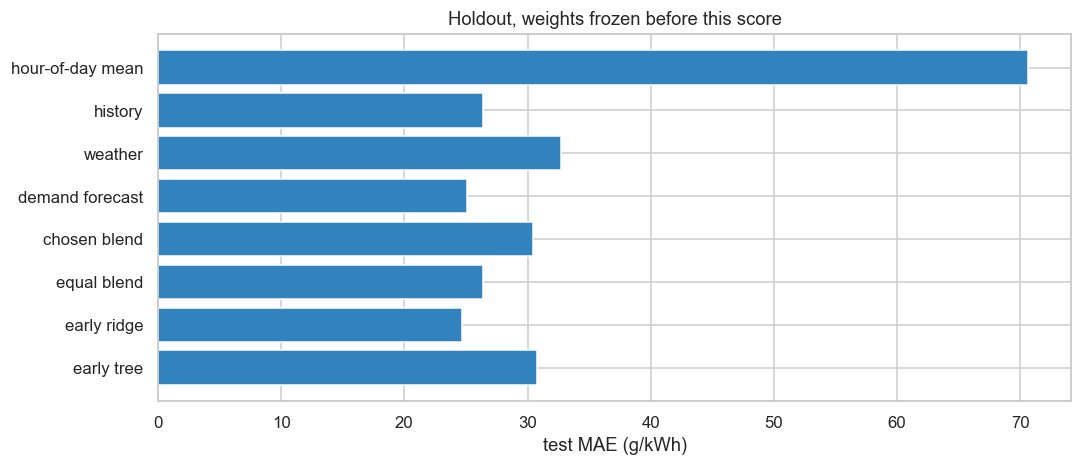

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.4))
ax.barh(table["model"], table["mae"], color="#3182bd")
ax.set_xlabel("test MAE (g/kWh)")
ax.invert_yaxis()
ax.set_title("Holdout, weights frozen before this score")
fig.tight_layout()
